# Inside the Model: Linear Regression

## The same change, a different line

**30–35 minutes**

If one measured response increases by 2, does it matter where that observation lies? Three points are enough to investigate how an ordinary least-squares line responds.

### Learning objectives

- predict whether a changed observation shifts or rotates a fitted line;
- connect the slope calculation to the observation's input value;
- distinguish a large residual from a large change in the fitted slope.

Record a prediction, calculate with a partner, and explain any revision before using Python. The optional challenge is additional.


### Before you start

**Prerequisite:** Linear Regression and Least Squares.

**Recall:** a prediction is $\hat y=a+bx$. The intercept $a$ moves the line up or down; the slope $b$ determines its tilt. A residual is $y-\hat y$. Least squares chooses **both** coefficients to minimise the sum of squared residuals. Dividing that sum by a fixed positive number gives the same fitted line.


### Our three observations

| Input $x$ | Original response $y$ |
|--:|--:|
| −1 | −1 |
| 0 | 0 |
| 1 | 1 |

Keep the inputs fixed and fit an intercept, with equal row weights and no regularisation.

---

## 1. Predict before calculating

**About 4 minutes · No Python**

The original line is $\hat y=x$. In the **Centre** experiment, change only the response at $x=0$ from 0 to 2, then refit.

Will the new line become steeper, become flatter, or keep the same slope? Will it move vertically? Sketch a line and justify your prediction. It need not pass through every observation.

**Your prediction and sketch:** _Write here._

the new points become (-1,-1), (0,2), (1,1).
the line passes through -1, -1; but the line is flatter and the slope is lesser than the original plot
it moves vertically, but to the right of the original line

## 2. Open the slope calculation

**About 8 minutes · No Python**

Our inputs have mean zero. For this special case, the least-squares solution simplifies to

$$b=\frac{\sum_i x_i y_i}{\sum_i x_i^2},\qquad a=\bar y.$$

Use this formula directly; it relies on the inputs having mean zero.

**One worked term:** for the unchanged first observation, $x_1y_1=(-1)(-1)=1$ and $x_1^2=1$. Now complete the other rows for the Centre experiment.

| $x$ | Centre response $y$ | Product $xy$ | Squared input $x^2$ |
|--:|--:|--:|--:|
| −1 | −1 | 1 | 1 |
| 0 | 2 | 0 | 0 |
| 1 | 1 | 1 | 1 |
| **Sum** | 2 | 2 | 2 |

Calculate $a$ and $b$, then compare them with your sketch. Which term explains what happened to the slope? Explain why an unchanged slope would **not** mean unchanged predictions.

**Your calculation and explanation:** _Write here._
a comes out to be 2/3 and b comes out to be 1. The slope didn't change but the predictions did as the line moved upward. For every value of x, now there is a different y according to the new line. 
<details>
<summary>Hint</summary>

Track the numerator and the response mean separately. Which one includes the response at $x=0$?

</details>


## 3. Put the same change at the edge

**About 8 minutes · No Python**

Return to the original data. This time change only the response at $x=1$ from 1 to 3. Call this the **Edge** experiment. The response change is still +2; it is **not** added on top of the Centre change.

Before calculating, predict whether this line will have the same slope and intercept as the Centre line. Explain what now changes in the numerator of the slope formula.

**Your new prediction:** Since the new points now become (-1,-1) (0,0) (1,3); the slope would change because of the new point, and it will not pass through the origin anymore.

| Experiment | Responses at $x=(-1,0,1)$ | Intercept $a$ | Slope $b$ |
|:--|:--|--:|--:|
| Original | $(−1,0,1)$ | 0 | 1 |
| Centre | $(−1,2,1)$ | 2/3 | 1 |
| Edge | $(−1,0,3)$ | 4/3 | 2 |

Calculate the residual **at the changed observation** in each refitted dataset. Does the larger residual necessarily identify the change that rotated the line more?

**Your comparison:** _Write here. Keep your original prediction visible._

the original dataset does not suffer. In the centre dataset, at x = 0, y_pred comes out to be 1 => the residual is 1. 

For the Edge case, at x = 1 y_pred comes out to be 2 while originally it is 3 => the residual is 3.

I feel the edge case has rotated the line more than the centre case because in the former, both the intercept and the slope has changed.


---

## 4. Verify with Python

**About 7 minutes · Begin after Sections 1–3**

Replace the three `None` values. `np.sum(x * y)` calculates the numerator and `np.mean(y)` calculates the mean response. Both changed datasets have the same mean, so they share one intercept.

The supplied cells then compare your coefficients with `LinearRegression` and plot the two experiments on matching axes. Explain any difference before correcting your calculation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

x = np.array([-1, 0, 1], dtype=float)
y_original = np.array([-1, 0, 1], dtype=float)
y_centre = np.array([-1, 2, 1], dtype=float)
y_edge = np.array([-1, 0, 3], dtype=float)

In [2]:
# ADD YOUR CODE HERE -- replace the three None values.
b_centre = np.sum(x*y_centre)/np.sum(x**2)
b_edge = np.sum(x*y_edge)/np.sum(x**2)
a = np.mean(y_edge)


Your Centre intercept and slope: 0.6666666666666666 1.0
Sklearn Centre: 0.6666666666666666 0.9999999999999993
Your Edge intercept and slope: 0.6666666666666666 2.0
Sklearn Edge: 0.6666666666666666 1.9999999999999993
Residual at changed Centre point: 1.3333333333333335
Residual at changed Edge point: 0.3333333333333335


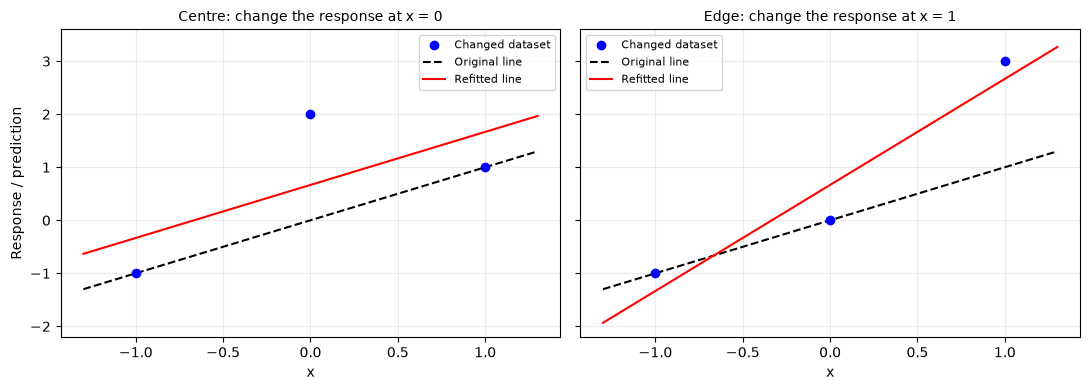

In [3]:
if a is None or b_centre is None or b_edge is None:
    print('Complete the three coefficients, then rerun this cell.')
else:
    centre_model = LinearRegression().fit(x.reshape(-1, 1), y_centre)
    edge_model = LinearRegression().fit(x.reshape(-1, 1), y_edge)
    print('Your Centre intercept and slope:', a, b_centre)
    print('Sklearn Centre:', centre_model.intercept_, centre_model.coef_[0])
    print('Your Edge intercept and slope:', a, b_edge)
    print('Sklearn Edge:', edge_model.intercept_, edge_model.coef_[0])
    print('Residual at changed Centre point:', y_centre[1] - a)
    print('Residual at changed Edge point:', y_edge[2] - (a + b_edge))

    responses = [y_centre, y_edge]
    slopes = [b_centre, b_edge]
    titles = ['Centre: change the response at x = 0', 'Edge: change the response at x = 1']
    x_plot = np.linspace(-1.3, 1.3, 100)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
    for i in range(2):
        axes[i].scatter(x, responses[i], color='blue', label='Changed dataset', zorder=3)
        axes[i].plot(x_plot, x_plot, color='black', linestyle='dashed', label='Original line')
        axes[i].plot(x_plot, a + slopes[i] * x_plot, color='red', label='Refitted line')
        axes[i].set_title(titles[i], fontsize=10)
        axes[i].set_xlabel('x')
        axes[i].set_ylim(-2.2, 3.6)
        axes[i].grid(True, alpha=0.25)
        axes[i].legend(fontsize=8)
    axes[0].set_ylabel('Response / prediction')
    plt.tight_layout()
    plt.show()


---

## 5. Explain the mechanism

**About 5 minutes**

1. Why does the Centre response contribute nothing to the slope numerator but still affect the fitted line?
2. Both responses increased by 2. Why do the slopes respond differently? Refer to $xy$, not simply to “an outlier”.
3. Would this experiment justify deleting a real observation with an extreme input? What information about the measurement would you need first?

**Your answers:** _Use one or two sentences for each._

1. The center response has the middle value changed, thats why the slope stays the same but the fitted line moves up by a bit.

2. The difference is which point was changed, if the last point is changed, the new line has to fit all the three points with one of them at the end. Whereas, if the middle point is changed then the slope does not change because 2 points are weighing down the line. We can relate to this with the concept of center of mass.

3. That depends on the position of the point. If the point is located at the edge, the slope changes but if it is located at the centre, the slope stays the same, but the intercept changes. So if we do want to delete an outlier, we would first need to understand the location of the point.

## Optional Master's challenge

**A further 5–8 minutes**

Now consider any fixed inputs that are not all equal. With an intercept fitted, the OLS slope can be written as

$$b=\frac{\sum_i(x_i-\bar{x})y_i}{S_{xx}},\qquad S_{xx}=\sum_i(x_i-\bar{x})^2.$$

Change only response $y_j$ by $\Delta y$. Derive the change in slope without refitting the whole line. Use your result to explain what happens when $x_j$ is at, above or below the input mean. Which position produces the largest absolute slope change for a fixed $|\Delta y|$?

<details>
<summary>Hint</summary>

The inputs, their mean and the denominator stay fixed. Only one term in the numerator changes.

</details>

**Your argument:** _Write here._

the change in the slope comes out to be the difference between the xj and delx and we multiply by dely and divide by Sxx. Pretty much the same as the original one, just that instead of yj we are changing dely. 

when xj is at the mean, the change will be 0, when it is above the mean, the change will be positive, and when it is below the mean, the change will be negative or the slope will reduce. But this will also depend on the signage of dely i.e. if dely is +ve, the change will be +ve, despite xj being below the mean; and vice versa.

In total, there will be 5 cases.

---

## Takeaway

Complete: **“To predict how a response change affects the slope, I need to know both the change in the response and the position of xj.”**
